In [5]:
import polars as pl
import matplotlib.pyplot as plt
import numpy as np

In [27]:
params = [12*4*512**2, 12*8*512**2, 12*8*128**2, 12*4*128**2]
loss = [1.63, 1.49, 2.05, 2.21]

[]

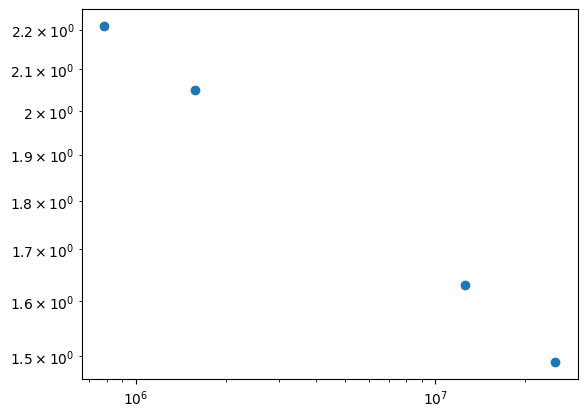

In [30]:
plt.scatter(params, loss)
plt.loglog()

In [3]:
params

[12582912, 25165824]

In [2]:
df = pl.read_csv("wandb5.csv")

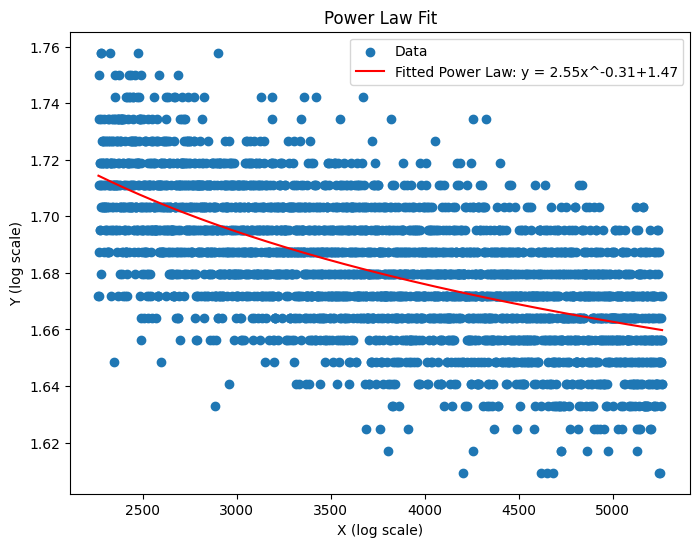

In [26]:
from scipy.optimize import curve_fit

# Generate example data (optional, replace with your actual data)
y_data = df.select("whole-dragon-366 - loss").to_numpy().flatten()
x_data = (np.arange(y_data.size).astype(np.float32) + 1)

y_data = y_data[-3000:]
x_data = x_data[-3000:]

# Define the power law function
def power_law(x, a, b, c):
    return a * x**b + c

# Fit the power law using curve_fit
params, covariance = curve_fit(power_law, x_data, y_data, p0=[1, 0, 1], maxfev=10000) # p0 provides initial guesses

a_fit, b_fit, c_fit = params

# Plot the results
plt.figure(figsize=(8, 6))
plt.scatter(x_data, y_data, label='Data')
plt.plot(x_data, power_law(x_data, a_fit, b_fit, c_fit), color='red', label=f'Fitted Power Law: y = {a_fit:.2f}x^{b_fit:.2f}+{c_fit:.2f}')
# plt.xscale('log')
# plt.yscale('log')
plt.xlabel('X (log scale)')
plt.ylabel('Y (log scale)')
plt.title('Power Law Fit')
plt.legend()
# plt.grid(True)
# plt.xlim(0, 10)
plt.show()